In [1]:
# เฉลย: ย้ายไปทำงานที่โฟลเดอร์ labs/ (ที่มี data/ และ mlia.py)
import os, sys
if os.path.basename(os.getcwd()) == "solution":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

# Mini-challenge · คัดกรองโรคหัวใจ (≈ 30 นาที หรือการบ้าน)

ใช้ทุกอย่างจาก Lab 1–3 กับโจทย์ใหม่: ทำนายว่าผู้ป่วยที่มาด้วยอาการเจ็บหน้าอก **มีหลอดเลือดหัวใจตีบ** (`target = 1`) หรือไม่
จากผลตรวจ 13 อย่าง — โจทย์นี้มี **feature แบบหมวดหมู่ (categorical)** ซึ่งต้องจัดการต่างจากตัวเลข

| คอลัมน์ | ความหมาย | ชนิด |
|---|---|---|
| `age`, `sex` | อายุ, เพศ (1 = ชาย) | ตัวเลข / 0-1 |
| `cp` | ชนิดการเจ็บหน้าอก (1 typical angina, 2 atypical, 3 non-anginal, 4 asymptomatic) | **หมวดหมู่** |
| `trestbps`, `chol` | ความดันขณะพัก (mmHg), cholesterol (mg/dL) | ตัวเลข |
| `fbs` | น้ำตาลขณะอดอาหาร > 120 mg/dL | 0-1 |
| `restecg` | ผล ECG ขณะพัก (0, 1, 2) | **หมวดหมู่** |
| `thalach`, `exang`, `oldpeak` | ชีพจรสูงสุดขณะออกกำลัง, เจ็บหน้าอกขณะออกกำลัง, ST depression | ตัวเลข / 0-1 |
| `slope` | ความชันของ ST segment (1 up, 2 flat, 3 down) | **หมวดหมู่** |
| `ca` | จำนวนหลอดเลือดหลักที่เห็นจาก fluoroscopy (0–3) | ตัวเลข (มี missing) |
| `thal` | thallium stress test (3 normal, 6 fixed defect, 7 reversible defect) | **หมวดหมู่** (มี missing) |

**ทำเองให้มากที่สุด** — TODO ในโจทย์นี้ให้ hint น้อยกว่า lab ปกติ

⚠️ *เพื่อการเรียนรู้เท่านั้น — ไม่ใช่เครื่องมือทางการแพทย์*

*Data: Janosi, Steinbrunn, Pfisterer & Detrano (1989). Heart Disease [Cleveland subset]. UCI Machine Learning Repository, doi:10.24432/C52P4X — CC BY 4.0*

In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from mlia import show_check, RANDOM_STATE

heart = pd.read_csv("data/heart.csv")
CATEGORICAL = ["cp", "restecg", "slope", "thal"]
NUMERIC = ["age", "sex", "trestbps", "chol", "fbs", "thalach", "exang", "oldpeak", "ca"]
X, y = heart[CATEGORICAL + NUMERIC], heart["target"]
print(heart.shape, f"· มีโรค {y.mean():.0%}")
heart.head()

(303, 14) · มีโรค 46%


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0.0,6.0,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3.0,3.0,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2.0,7.0,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0.0,3.0,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0.0,3.0,0


## C.1 แบ่ง train / test

เหมือน Lab 1: 80/20, `stratify=y`, `random_state=RANDOM_STATE`

In [3]:
# ✔ TODO C.1: แบ่ง X, y เป็น X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
show_check(len(X_test) == 61, "แบ่งได้ train 242 / test 61", "ตรวจ test_size และ stratify")

✅ แบ่งได้ train 242 / test 61


## C.2 ColumnTransformer: จัดการตัวเลขกับหมวดหมู่ต่างกัน

`cp = 4` ไม่ได้ "มากกว่า" `cp = 2` เป็นสองเท่า — มันคือ **ชื่อหมวด** ถ้าใส่เป็นตัวเลขตรง ๆ logistic regression จะเข้าใจผิด
**One-hot encoding** แตกเป็นคอลัมน์ 0/1 ต่อหมวด (`cp_1`, `cp_2`, …)

`ColumnTransformer` ส่งแต่ละกลุ่มคอลัมน์เข้า pipeline ย่อยของตัวเอง:
- ตัวเลข → `SimpleImputer(strategy="median")` → `StandardScaler()`
- หมวดหมู่ → `SimpleImputer(strategy="most_frequent")` → `OneHotEncoder(handle_unknown="ignore")`

In [4]:
# ✔ TODO C.2: เติม pipeline ย่อยของ "cat" ให้ครบ (imputer most_frequent → OneHotEncoder(handle_unknown="ignore", sparse_output=False))
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False)), CATEGORICAL),
])
Xt = preprocess.fit_transform(X_train)
print(Xt.shape)
list(preprocess.get_feature_names_out())

(242, 22)


['num__age',
 'num__sex',
 'num__trestbps',
 'num__chol',
 'num__fbs',
 'num__thalach',
 'num__exang',
 'num__oldpeak',
 'num__ca',
 'cat__cp_1.0',
 'cat__cp_2.0',
 'cat__cp_3.0',
 'cat__cp_4.0',
 'cat__restecg_0.0',
 'cat__restecg_1.0',
 'cat__restecg_2.0',
 'cat__slope_1.0',
 'cat__slope_2.0',
 'cat__slope_3.0',
 'cat__thal_3.0',
 'cat__thal_6.0',
 'cat__thal_7.0']

In [5]:
show_check(Xt.shape == (242, 22), "ได้ 22 คอลัมน์หลัง one-hot (9 ตัวเลข + 13 หมวด)", "ตรวจ OneHotEncoder ในส่วน cat")

✅ ได้ 22 คอลัมน์หลัง one-hot (9 ตัวเลข + 13 หมวด)


## C.3 เทียบ Logistic regression กับ Random forest ด้วย 5-fold CV

ต่อ `preprocess` เข้ากับ model แต่ละตัวด้วย `make_pipeline` แล้วใช้ `cross_validate` (scoring ROC-AUC และ recall)

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ✔ TODO C.3: สร้าง models = {"Logistic regression": pipeline, "Random forest": pipeline} แล้วเก็บผล CV ใน cv_table
models = {
    "Logistic regression": make_pipeline(preprocess, LogisticRegression(max_iter=1000)),
    "Random forest": make_pipeline(preprocess, RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                                      random_state=RANDOM_STATE, n_jobs=-1)),
}
cv_table = pd.DataFrame({
    name: {s: cross_validate(m, X_train, y_train, cv=cv, scoring=s)["test_score"].mean() for s in ["roc_auc", "recall"]}
    for name, m in models.items()})
cv_table

,Logistic regression,Random forest
roc_auc,0.906525,0.899822
recall,0.792490,0.782609


In [7]:
show_check(cv_table.loc["roc_auc"].min() > 0.85, "ทั้งสอง model ได้ CV ROC-AUC > 0.85", "ROC-AUC ต่ำผิดปกติ — ตรวจ pipeline")

✅ ทั้งสอง model ได้ CV ROC-AUC > 0.85


## C.4 SHAP ของ Random Forest

สอง model ใกล้กันมากอีกแล้ว — ลองอธิบาย Random Forest: fit กับ train → แปลง X_test ด้วยขั้น preprocess (`rf[:-1].transform`) → `TreeExplainer(rf[-1])` → beeswarm ของคลาส 1

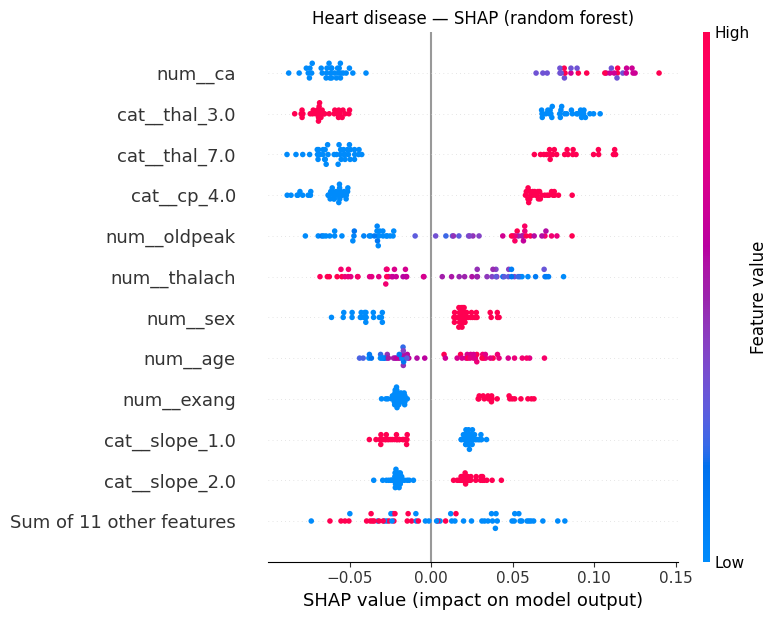

In [8]:
rf = models["Random forest"].fit(X_train, y_train)
names = rf[:-1].get_feature_names_out()

# ✔ TODO C.4: คำนวณ SHAP ของ X_test (คลาส 1) เก็บใน sv แล้ววาด beeswarm
X_test_t = pd.DataFrame(rf[:-1].transform(X_test), columns=names)
sv = shap.TreeExplainer(rf[-1])(X_test_t)[:, :, 1]
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("Heart disease — SHAP (random forest)"); plt.tight_layout(); plt.show()

In [9]:
show_check(sv.shape == (61, 22), "ได้ SHAP 61 คน × 22 feature", "ตรวจว่าเลือกคลาส 1 ด้วย [:, :, 1]")

✅ ได้ SHAP 61 คน × 22 feature


## คำถามท้าย challenge

1. feature ไหนสำคัญที่สุด 3 อันดับ? สมเหตุสมผลทางคลินิกไหม (ลองค้น "thallium stress test", "asymptomatic chest pain")
2. `cat__cp_4.0` (asymptomatic) ดันความเสี่ยง **ขึ้น** — แปลกไหมที่ "ไม่มีอาการเจ็บแบบ angina" กลับเสี่ยงกว่า? (hint: ใครถูกส่งมาตรวจ)
3. ถ้าจะ deploy model นี้เป็น app แบบ Lab 4 ต้องแก้ไฟล์ไหนบ้าง? (`train.py`, `model_utils.py`, `app.py` — input แบบหมวดหมู่ควรเป็น `st.selectbox`)
4. ข้อมูลมาจากโรงพยาบาลเดียวในสหรัฐฯ ปี 1988 — ก่อนใช้กับผู้ป่วยไทย ต้องตรวจสอบอะไรเพิ่ม?